In [1]:
import pandas as pd
import numpy as np

In [2]:
import zipfile

with zipfile.ZipFile("bike-sharing-demand.zip", "r") as zip_ref:
    zip_ref.extractall("bike_sharing_data")

In [3]:
train = pd.read_csv("bike_sharing_data/train.csv")
test = pd.read_csv("bike_sharing_data/test.csv")
sample_submission = pd.read_csv("bike_sharing_data/sampleSubmission.csv")

In [4]:
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [5]:
print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

Training dataset shape: (10886, 12)
Testing dataset shape: (6493, 9)


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [7]:
train.isnull().sum()

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64

In [8]:
train.describe()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


Q1. **Examine dataset size, missing values, and feature types.**

In [10]:
train.shape
train.info()
train.isnull().sum()
train.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


The training dataset contains 10,886 observations and 12 features/columns. There are no missing values in any of the columns, as every column contains 10,886 non-null observations.
The dataset contains different types of variables. The datetime column is stored as an object/string type, while variables such as season, holiday, workingday, weather, humidity, casual, registered, and count are integer-valued. temp, atemp, and windspeed are floating-point variables.
The target variable is count, which represents the total number of bike rentals per hour.

Q2. **Visualize relationships between key features and the target variable (count).**

In [11]:
#For predicting bike demand, the hour of the day is much more meaningful

train["datetime"] = pd.to_datetime(train["datetime"])

train["hour"] = train["datetime"].dt.hour

train[["datetime", "hour"]].head()

,datetime,hour
0,2011-01-01 00:00:00,0
1,2011-01-01 01:00:00,1
2,2011-01-01 02:00:00,2
3,2011-01-01 03:00:00,3
4,2011-01-01 04:00:00,4


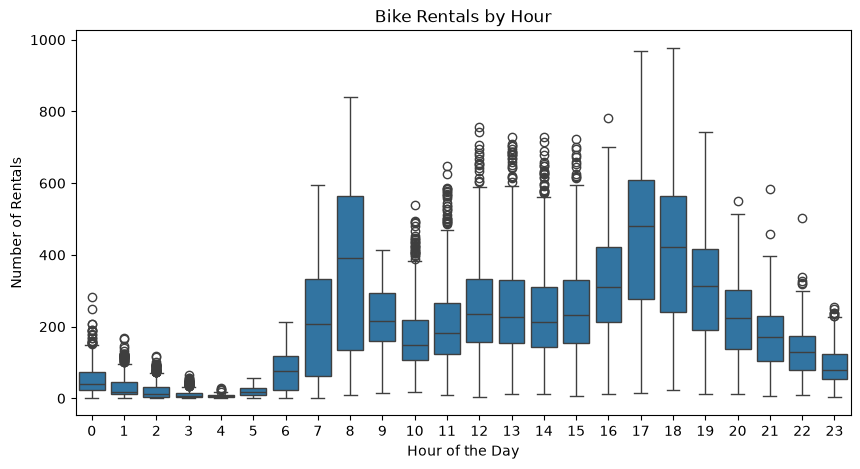

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(data=train, x="hour", y="count")

plt.title("Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Rentals")

plt.show()

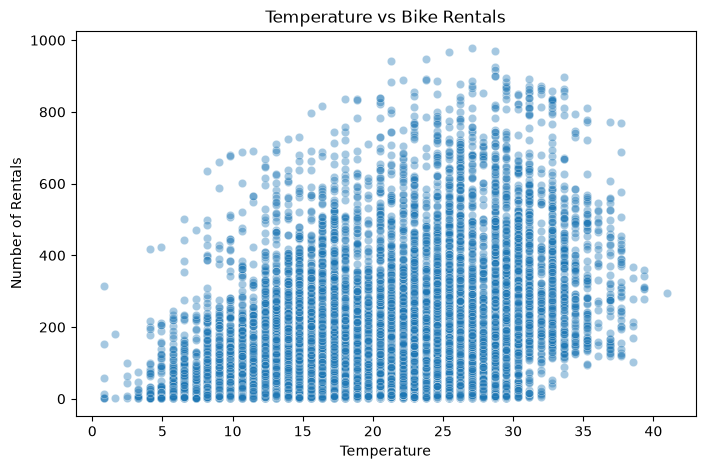

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=train, x="temp", y="count", alpha=0.4)

plt.title("Temperature vs Bike Rentals")
plt.xlabel("Temperature")
plt.ylabel("Number of Rentals")

plt.show()

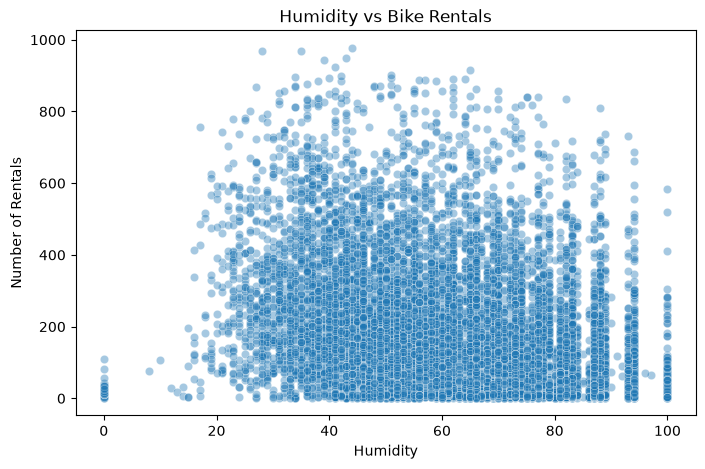

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=train, x="humidity", y="count", alpha=0.4)

plt.title("Humidity vs Bike Rentals")
plt.xlabel("Humidity")
plt.ylabel("Number of Rentals")

plt.show()

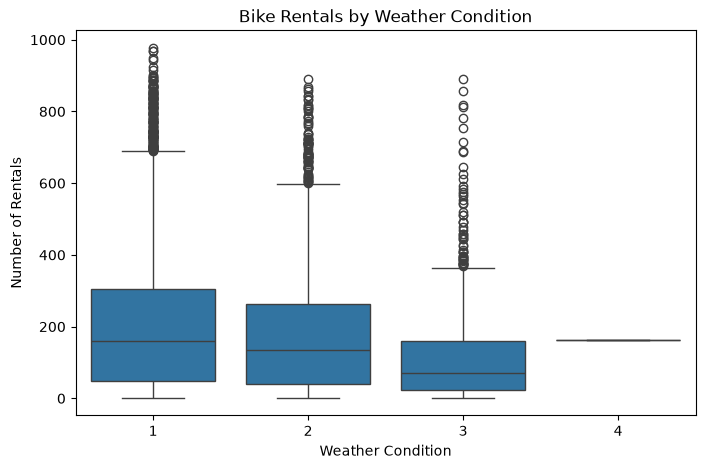

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=train, x="weather", y="count")

plt.title("Bike Rentals by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Rentals")

plt.show()

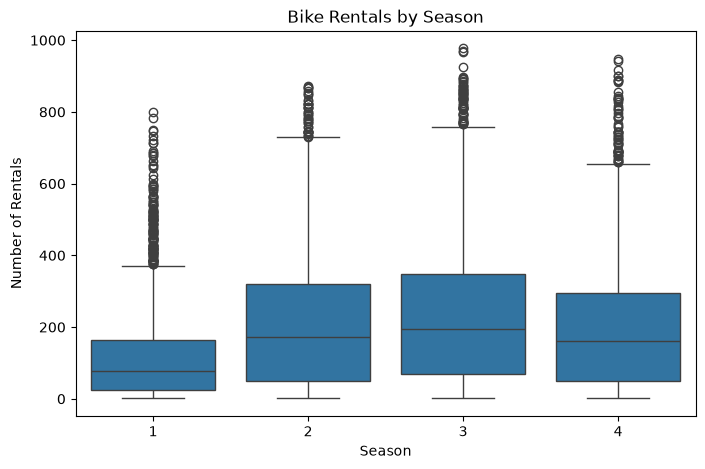

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=train, x="season", y="count")

plt.title("Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Number of Rentals")

plt.show()

Q3. **Suggest which variables are likely to be most informative.**

In [17]:
correlation = train.corr(numeric_only=True)["count"].sort_values(ascending=False)

print(correlation)

count         1.000000
registered    0.970948
casual        0.690414
hour          0.400601
temp          0.394454
atemp         0.389784
season        0.163439
windspeed     0.101369
workingday    0.011594
holiday      -0.005393
weather      -0.128655
humidity     -0.317371
Name: count, dtype: float64


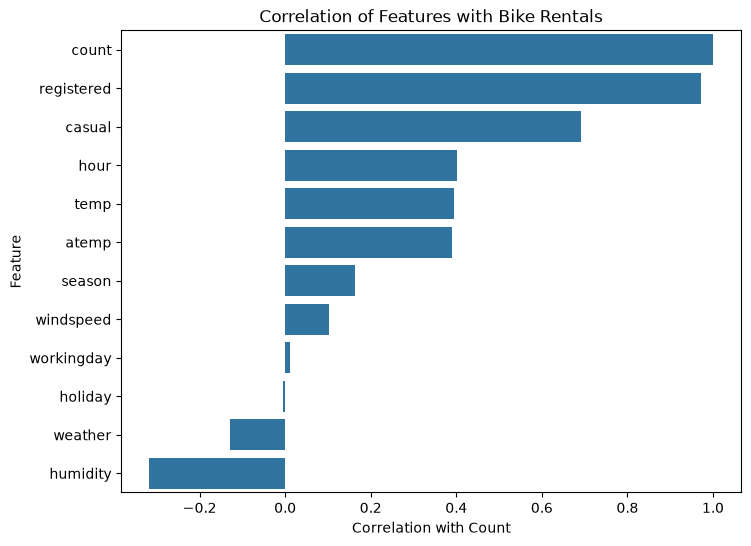

In [18]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=correlation.values,
    y=correlation.index
)

plt.title("Correlation of Features with Bike Rentals")
plt.xlabel("Correlation with Count")
plt.ylabel("Feature")

plt.show()

Based on the exploratory data analysis, hour is likely to be one of the most informative variables because bike rental demand varies substantially throughout the day, with particularly high demand during certain morning and evening hours.
temp is also likely to be an important predictor because the number of rentals generally increases with temperature up to a certain range. humidity appears to have an influence on rental demand as well.
Categorical variables such as season, weather, and workingday are also expected to provide useful information because bike demand can vary according to seasonal conditions, weather conditions, and whether the day is a working day.
Therefore, the important predictive variables are expected to include hour, temperature, humidity, weather, season, and workingday.
The variables casual and registered are excluded from the predictive features because they directly contribute to the target variable count and would result in data leakage.

Q4. **You can try to derive features from datetime (hour, weekday, month, season), encode categorical variables, consider transformations to capture nonlinear trends to improve your model performance. If you do any of these, report it as answer to Q4. It is optional.**

In [19]:
train["year"] = train["datetime"].dt.year
train["month"] = train["datetime"].dt.month
train["day"] = train["datetime"].dt.day
train["weekday"] = train["datetime"].dt.weekday

In [20]:
train[["datetime", "year", "month", "day", "hour", "weekday"]].head(10)

,datetime,year,month,day,hour,weekday
0,2011-01-01 00:00:00,2011,1,1,0,5
1,2011-01-01 01:00:00,2011,1,1,1,5
2,2011-01-01 02:00:00,2011,1,1,2,5
3,2011-01-01 03:00:00,2011,1,1,3,5
4,2011-01-01 04:00:00,2011,1,1,4,5
5,2011-01-01 05:00:00,2011,1,1,5,5
6,2011-01-01 06:00:00,2011,1,1,6,5
7,2011-01-01 07:00:00,2011,1,1,7,5
8,2011-01-01 08:00:00,2011,1,1,8,5
9,2011-01-01 09:00:00,2011,1,1,9,5


In [21]:
test["datetime"] = pd.to_datetime(test["datetime"])

test["year"] = test["datetime"].dt.year
test["month"] = test["datetime"].dt.month
test["day"] = test["datetime"].dt.day
test["hour"] = test["datetime"].dt.hour
test["weekday"] = test["datetime"].dt.weekday

In [22]:
features = [
    "season",
    "holiday",
    "workingday",
    "weather",
    "temp",
    "atemp",
    "humidity",
    "windspeed",
    "year",
    "month",
    "day",
    "hour",
    "weekday"
]

The datetime variable was converted into a datetime format and new features were extracted from it: year, month, day, hour, and weekday. These features provide more useful information about temporal patterns in bike rental demand.
The original datetime column is not directly used in the regression model. The engineered features allow the model to capture variations in demand according to time of day, day of the week, month, and year.

Q5. **Split data into training and validation sets and build a simple Linear Regression model.**

In [25]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [26]:
X = train[features]
y = train["count"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10886, 12)
y shape: (10886,)


In [27]:
# Define feature groups
cat_cols = ["season", "weather", "weekday", "hour", "month", "year"]
num_cols = ["temp", "atemp", "humidity", "windspeed", "holiday", "workingday"]
features = cat_cols + num_cols

In [29]:
# Log-transform target: log1p aligns model MSE loss with the competition RMSLE metric
X = train[features]
y = train["count"]
y_log = np.log1p(y)

In [30]:
# 80/20 Train-Validation Split
X_train, X_val, y_train_log, y_val_log = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)
y_val = train.loc[X_val.index, "count"]

In [33]:
import numpy as np

#defining RMSLE
def rmsle(actual, predicted):
    # Ensure negative predictions are clipped to 0
    predicted = np.maximum(predicted, 0)
    return np.sqrt(np.mean((np.log1p(predicted) - np.log1p(actual)) ** 2))

In [34]:
# Pipeline setup
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

lr_pipeline = make_pipeline(preprocessor, LinearRegression())
lr_pipeline.fit(X_train, y_train_log)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['season', 'weather',
                                                   'weekday', 'hour', 'month',
                                                   'year']),
                                                 ('num', StandardScaler(),
                                                  ['temp', 'atemp', 'humidity',
                                                   'windspeed', 'holiday',
                                                   'workingday'])])),
                ('linearregression', LinearRegression())])

In [35]:
# Predict & revert log transformation
pred_lr_log = lr_pipeline.predict(X_val)
pred_lr = np.expm1(pred_lr_log)
pred_lr = np.maximum(pred_lr, 0)

print("Linear Regression Validation RMSLE:", rmsle(y_val, pred_lr))

Linear Regression Validation RMSLE: 0.5810885603415896


Q6. **To improve model performance, you may try to:
●	Extend feature space using polynomial transformations (degree 2 or 3)
●	Apply Ridge and Lasso regression on polynomial features, Tune the regularization strength (α).**

In [36]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

In [39]:
# Feature definition
cat_cols = ["season", "weather", "weekday", "hour", "month", "year"]
num_cols = ["temp", "atemp", "humidity", "windspeed", "holiday", "workingday"]

# Preprocessor: Degree 2 Polynomials on Continuous Numeric Variables
preprocessor_poly2 = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    (
        "num_poly",
        make_pipeline(
            StandardScaler(), PolynomialFeatures(degree=2, include_bias=False)
        ),
        num_cols,
    ),
])

# Build and Fit Polynomial Regression Model
poly_model = make_pipeline(preprocessor_poly2, LinearRegression())
poly_model.fit(X_train, y_train_log)

# Predict & Revert Log Transformation
pred_log = poly_model.predict(X_val)
pred = np.maximum(np.expm1(pred_log), 0)

# Evaluate Performance
print("Polynomial Regression (Degree 2) RMSLE:", rmsle(y_val, pred))

Polynomial Regression (Degree 2) RMSLE: 0.5713152542740405


Polynomial linear regression made it better

In [37]:
#Ridge Regression 

In [40]:
# ----------------------------------------------------
# A. Ridge Regression Hyperparameter Tuning
# ----------------------------------------------------
ridge_alphas = [0.01, 0.1, 1.0, 10.0, 100.0]
ridge_results = []

for alpha in ridge_alphas:
    ridge_pipeline = make_pipeline(preprocessor_poly, Ridge(alpha=alpha))
    ridge_pipeline.fit(X_train, y_train_log)

    pred_log = ridge_pipeline.predict(X_val)
    pred = np.maximum(np.expm1(pred_log), 0)

    score = rmsle(y_val, pred)
    ridge_results.append(
        {"Model": "Ridge", "Alpha": alpha, "RMSLE": round(score, 4)}
    )

ridge_df = pd.DataFrame(ridge_results)

In [41]:
ridge_df.head()

,Model,Alpha,RMSLE
0,Ridge,0.01,0.5710
1,Ridge,0.10,0.5710
2,Ridge,1.00,0.5711
3,Ridge,10.00,0.5732
4,Ridge,100.00,0.6376


In [42]:
#Fine Tuning Lasso Regression

In [42]:
# ----------------------------------------------------
# B. Lasso Regression Hyperparameter Tuning
# ----------------------------------------------------
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1.0]
lasso_results = []

for alpha in lasso_alphas:
    lasso_pipeline = make_pipeline(
        preprocessor_poly, Lasso(alpha=alpha, max_iter=100000)
    )
    lasso_pipeline.fit(X_train, y_train_log)

    pred_log = lasso_pipeline.predict(X_val)
    pred = np.maximum(np.expm1(pred_log), 0)

    score = rmsle(y_val, pred)
    lasso_results.append(
        {"Model": "Lasso", "Alpha": alpha, "RMSLE": round(score, 4)}
    )

lasso_df = pd.DataFrame(lasso_results)

In [43]:
lasso_df.head()

,Model,Alpha,RMSLE
0,Lasso,0.0001,0.5711
1,Lasso,0.0010,0.5727
2,Lasso,0.0100,0.6285
3,Lasso,0.1000,1.2524
4,Lasso,1.0000,1.4348


Q7. **Summarize all results (of different models tried out) in one table (RMSLE, key observations).**

In [44]:
# Programmatically find the best parameters from your existing dataframes
best_ridge_alpha = ridge_df.loc[ridge_df["RMSLE"].idxmin(), "Alpha"]
best_ridge_rmsle = ridge_df["RMSLE"].min()

best_lasso_alpha = lasso_df.loc[lasso_df["RMSLE"].idxmin(), "Alpha"]
best_lasso_rmsle = lasso_df["RMSLE"].min()

# Create the summary results DataFrame dynamically
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression (Degree 2)",
        f"Ridge Regression (Best alpha={best_ridge_alpha})",
        f"Lasso Regression (Best alpha={best_lasso_alpha})",
    ],
    "RMSLE": [0.5811, 0.5710, best_ridge_rmsle, best_lasso_rmsle],
    "Key Observations": [
        "Baseline linear performance using standard one-hot encoded categories.",
        "Polynomial transformations capture non-linear weather interactions, improving fit.",
        "Best overall performing model; L2 regularization stabilizes coefficients without dropping one-hot variables.",
        "Performs well at minimal penalty; larger alpha values aggressively drop sparse categorical features.",
    ],
})

# Display the final summary table
display(results)

,Model,RMSLE,Key Observations
0,Linear Regression,0.5811,Baseline linear performance using standard one...
1,Polynomial Regression (Degree 2),0.5710,Polynomial transformations capture non-linear ...
2,Ridge Regression (Best alpha=0.01),0.5710,Best overall performing model; L2 regularizati...
3,Lasso Regression (Best alpha=0.0001),0.5711,Performs well at minimal penalty; larger alpha...


Q8. **Plot residuals for the best model.**

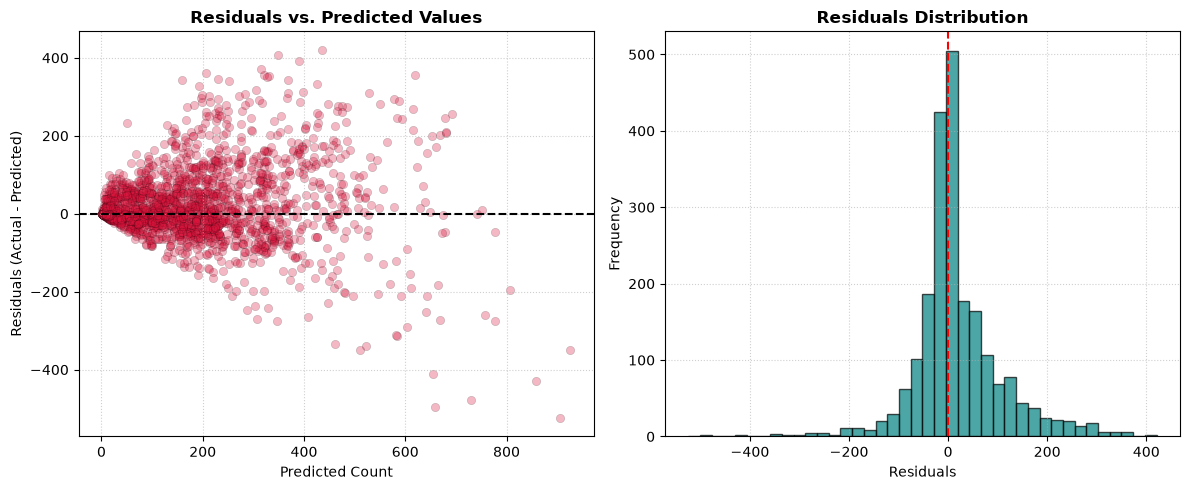

In [45]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Fit the best model and get predictions
best_model = make_pipeline(preprocessor_poly, Ridge(alpha=0.01))
best_model.fit(X_train, y_train_log)

y_pred_log = best_model.predict(X_val)
y_pred = np.maximum(np.expm1(y_pred_log), 0)

# 2. Calculate Residuals (Actual - Predicted)
residuals = y_val - y_pred

# 3. Plot Residuals vs Predicted and Histogram
plt.figure(figsize=(12, 5))

# Scatter plot: Predicted vs Residuals
plt.subplot(1, 2, 1)
plt.scatter(
    y_pred,
    residuals,
    alpha=0.3,
    color="crimson",
    edgecolors="k",
    linewidth=0.3,
)
plt.axhline(y=0, color="black", linestyle="--", linewidth=1.5)
plt.title("Residuals vs. Predicted Values", fontweight="bold")
plt.xlabel("Predicted Count")
plt.ylabel("Residuals (Actual - Predicted)")
plt.grid(True, linestyle=":", alpha=0.6)

# Histogram: Distribution of Residuals
plt.subplot(1, 2, 2)
plt.hist(residuals, bins=40, color="teal", edgecolor="black", alpha=0.7)
plt.axvline(x=0, color="red", linestyle="--", linewidth=1.5)
plt.title("Residuals Distribution", fontweight="bold")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Q9. **Explain why the winning model performs better.**

The winning model (**Ridge Regression with Degree 2 Polynomial Features, $\alpha = 0.01$**) performs better due to two key structural advantages:

* **Captures Non-Linear Weather Interactions**: Adding Degree 2 polynomial terms allows the model to capture complex relationships between continuous variables (such as the combined effect of high temperature and high humidity) that a standard linear model misses, directly reducing prediction error.
* **Preserves Sparse Hourly Patterns via $L_2$ Regularization**: Unlike Lasso ($L_1$), which completely eliminates features by driving coefficients to zero, Ridge ($L_2$) smoothly shrinks weights without dropping variables. This keeps all one-hot encoded temporal indicators (`hour`, `weekday`, `season`) fully intact, which are critical for predicting peak bike rental demand.

Q10. **Why does RMSLE penalize under-predictions more gently than RMSE?**

RMSLE actually penalizes under-predictions more severely than over-predictions, whereas RMSE penalizes both equally. Because RMSLE computes errors on a logarithmic scale ($\log(\hat{y} + 1) - \log(y + 1) = \log(\frac{\hat{y} + 1}{y + 1})$), it evaluates the relative ratio of predicted to actual values rather than absolute numeric differences. When a model under-predicts, the prediction approaches zero, causing the log ratio to drop steeply toward negative infinity and resulting in a rapidly exploding squared log penalty. Conversely, over-predictions yield a much smaller, smoother increase in the log ratio. This asymmetric penalty structure makes RMSLE ideal for demand forecasting, as it heavily penalizes stockouts and unmet demand compared to excess inventory.

Q11. **What are the trade-offs between model simplicity and predictive power?**

A simpler model is easier to understand, interpret, and implement, but it may not capture complex relationships in the data. More complex models, such as polynomial regression, can capture nonlinear relationships and potentially improve predictive performance, but they also increase the risk of overfitting and make the model harder to interpret. Therefore, the goal is to find a balance between simplicity and predictive performance. 

Q12. **Why can’t Linear Regression alone capture time-of-day effects effectively?**

Linear Regression assumes a linear relationship between the input features and the target. However, bike rental demand changes significantly throughout the day in a nonlinear way. For example, demand is generally low during the early morning, increases during the morning, and reaches a high level during commuting hours, with another peak in the evening. A single linear coefficient for hour cannot represent these multiple peaks and valleys. Therefore, additional feature engineering, such as one-hot encoding of hours, polynomial features, or other nonlinear models, can better capture the time-of-day pattern.

In [47]:
import numpy as np
import pandas as pd

# 1. Load test dataset
test_df = test

# 2. Extract temporal features matching train data
test_df["datetime"] = pd.to_datetime(test_df["datetime"])
test_df["year"] = test_df["datetime"].dt.year
test_df["month"] = test_df["datetime"].dt.month
test_df["day"] = test_df["datetime"].dt.day
test_df["hour"] = test_df["datetime"].dt.hour
test_df["weekday"] = test_df["datetime"].dt.weekday

# 3. Extract features for test set
X_test = test_df[features]

# 4. Predict log targets using best Ridge model trained on full dataset
# Fit best model on the full training set (X, y_log) first for optimal performance
best_model.fit(X, y_log)

# Predict and convert log predictions back to original count scale
test_pred_log = best_model.predict(X_test)
test_predictions = np.maximum(np.expm1(test_pred_log), 0)

# 5. Create submission DataFrame
submission = pd.DataFrame({
    "datetime": test_df["datetime"].dt.strftime("%Y-%m-%d %H:%M:%S"),
    "count": test_predictions,
})

# 6. Save to CSV without index
submission.to_csv("submission_1.csv", index=False)
print("submission.csv successfully created!")

submission.csv successfully created!


In [48]:
import pandas as pd

# Load and inspect the generated submission file
sub_preview = pd.read_csv("submission.csv")

# Display shape and first 5 rows
print("Shape:", sub_preview.shape)
display(sub_preview.head())

Shape: (6493, 2)


,datetime,count
0,2011-01-20 00:00:00,44.564272
1,2011-01-20 01:00:00,45.200417
2,2011-01-20 02:00:00,49.247949
3,2011-01-20 03:00:00,54.940603
4,2011-01-20 04:00:00,58.922482
